# Chimera Biological Validation

Validates that Chimera's outputs are biologically meaningful:
1. Alpha separates known conserved vs. divergent gene categories
2. Cell-type-specific cross-species patterns are captured
3. Shared decoder faithfully reconstructs expression
4. The model captures genuine biology, not artifacts

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp_mod
from scipy.stats import spearmanr, mannwhitneyu

plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 150

adata = ad.read_h5ad('../data/processed/camex_human_monkey.h5ad')
state = np.load('../training/runs/iter31-mmd1k-masked-detached/final_state.npz')

alpha = state['alpha']
prior = state['prior']
delta_alpha = alpha - prior
residual_rms = state['residual_rms']
mu_shared_mean = state['mu_shared_mean']
species = state['species_labels']
cell_types = adata.obs['cell_type'].values

# Map ortholog group IDs to human gene names via the ortholog table
orth = pd.read_csv('../data/processed/ortholog_table.csv')
orth_map = dict(zip('ortho_' + orth['ortholog_group_id'].astype(str), orth['hsapiens_gene_name']))
gene_names = np.array([orth_map.get(n, n) for n in adata.var_names])

X = adata.X
if sp_mod.issparse(X): X_dense = X.toarray()
else: X_dense = np.asarray(X)

print(f'{len(alpha)} genes loaded, {(gene_names != adata.var_names.values).sum()} mapped to human symbols')

8430 genes loaded, 8430 mapped to human symbols


## 1. Gene Category Validation

Known biological categories should separate along the alpha axis:
- **Housekeeping genes** (ribosomal, metabolic): expected HIGH alpha (conserved)
- **Immune/surface markers**: expected LOWER alpha (species-divergent)

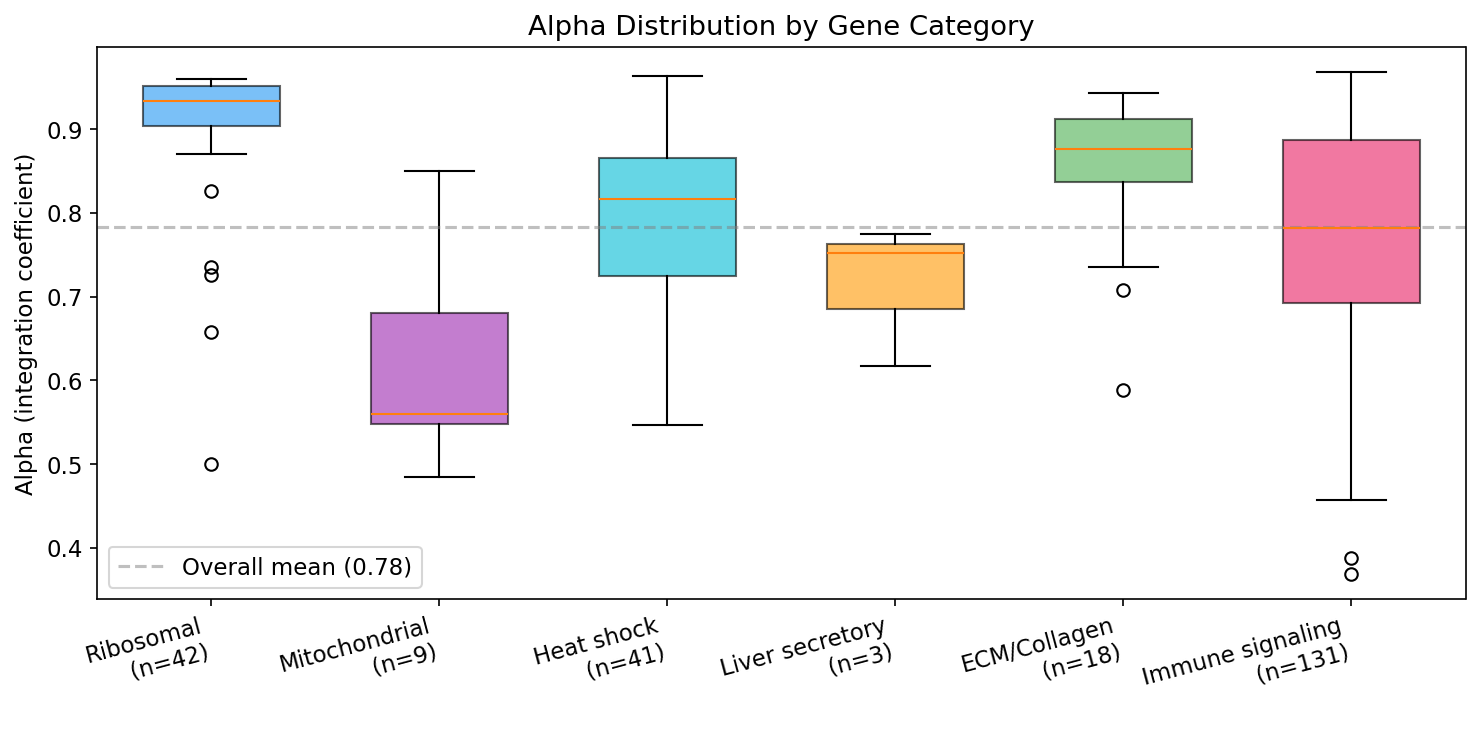


Mann-Whitney U tests (category vs all other genes):
  ECM/Collagen        : median=0.876 (higher), p=6.15e-03, n=18
  Heat shock          : median=0.817 (higher), p=6.99e-01, n=41
  Immune signaling    : median=0.782 (lower), p=5.09e-01, n=131
  Liver secretory     : median=0.752 (lower), p=2.08e-01, n=3
  Mitochondrial       : median=0.560 (lower), p=9.71e-04, n=9
  Ribosomal           : median=0.934 (higher), p=2.76e-14, n=42


In [2]:
# Define gene categories by name patterns
def classify_genes(names):
    categories = {}
    for i, name in enumerate(names):
        name_upper = str(name).upper()
        if name_upper.startswith(('RPL', 'RPS')):
            categories.setdefault('Ribosomal', []).append(i)
        elif name_upper.startswith('MT-'):
            categories.setdefault('Mitochondrial', []).append(i)
        elif name_upper.startswith(('COL', 'FN1', 'LAMA', 'LAMB')):
            categories.setdefault('ECM/Collagen', []).append(i)
        elif name_upper.startswith(('HLA-', 'H2-', 'MHC')):
            categories.setdefault('MHC/HLA', []).append(i)
        elif name_upper.startswith(('CD', 'IL', 'TNF', 'IFN', 'CXCL', 'CCL')):
            categories.setdefault('Immune signaling', []).append(i)
        elif name_upper.startswith(('HSP', 'DNAJ')):
            categories.setdefault('Heat shock', []).append(i)
        elif name_upper in ('ALB', 'TF', 'APOA1', 'APOB', 'APOC1', 'APOE', 'SERPINA1', 'FGA', 'FGB', 'FGG'):
            categories.setdefault('Liver secretory', []).append(i)
    return categories

cats = classify_genes(gene_names)

fig, ax = plt.subplots(figsize=(10, 5))
data, tick_labs, colors = [], [], []
color_map = {'Ribosomal': '#2196F3', 'Mitochondrial': '#9C27B0', 'Heat shock': '#00BCD4',
             'Liver secretory': '#FF9800', 'ECM/Collagen': '#4CAF50',
             'MHC/HLA': '#F44336', 'Immune signaling': '#E91E63'}

for cat_name in ['Ribosomal', 'Mitochondrial', 'Heat shock', 'Liver secretory',
                 'ECM/Collagen', 'MHC/HLA', 'Immune signaling']:
    if cat_name in cats and len(cats[cat_name]) >= 3:
        idx = cats[cat_name]
        data.append(alpha[idx])
        tick_labs.append(f'{cat_name}\n(n={len(idx)})')
        colors.append(color_map.get(cat_name, 'gray'))

bp = ax.boxplot(data, tick_labels=tick_labs, patch_artist=True, widths=0.6)
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)

ax.axhline(alpha.mean(), color='gray', linestyle='--', alpha=0.5, label=f'Overall mean ({alpha.mean():.2f})')
ax.set_ylabel('Alpha (integration coefficient)')
ax.set_title('Alpha Distribution by Gene Category')
ax.legend()
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

# Statistical tests
print('\nMann-Whitney U tests (category vs all other genes):')
for cat_name, idx in sorted(cats.items()):
    if len(idx) >= 3:
        other = np.setdiff1d(range(len(alpha)), idx)
        u, p = mannwhitneyu(alpha[idx], alpha[other], alternative='two-sided')
        direction = 'higher' if np.median(alpha[idx]) > np.median(alpha[other]) else 'lower'
        print(f'  {cat_name:20s}: median={np.median(alpha[idx]):.3f} ({direction}), p={p:.2e}, n={len(idx)}')

## 2. Cell-Type-Specific Expression Conservation

/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_22146/2821394867.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


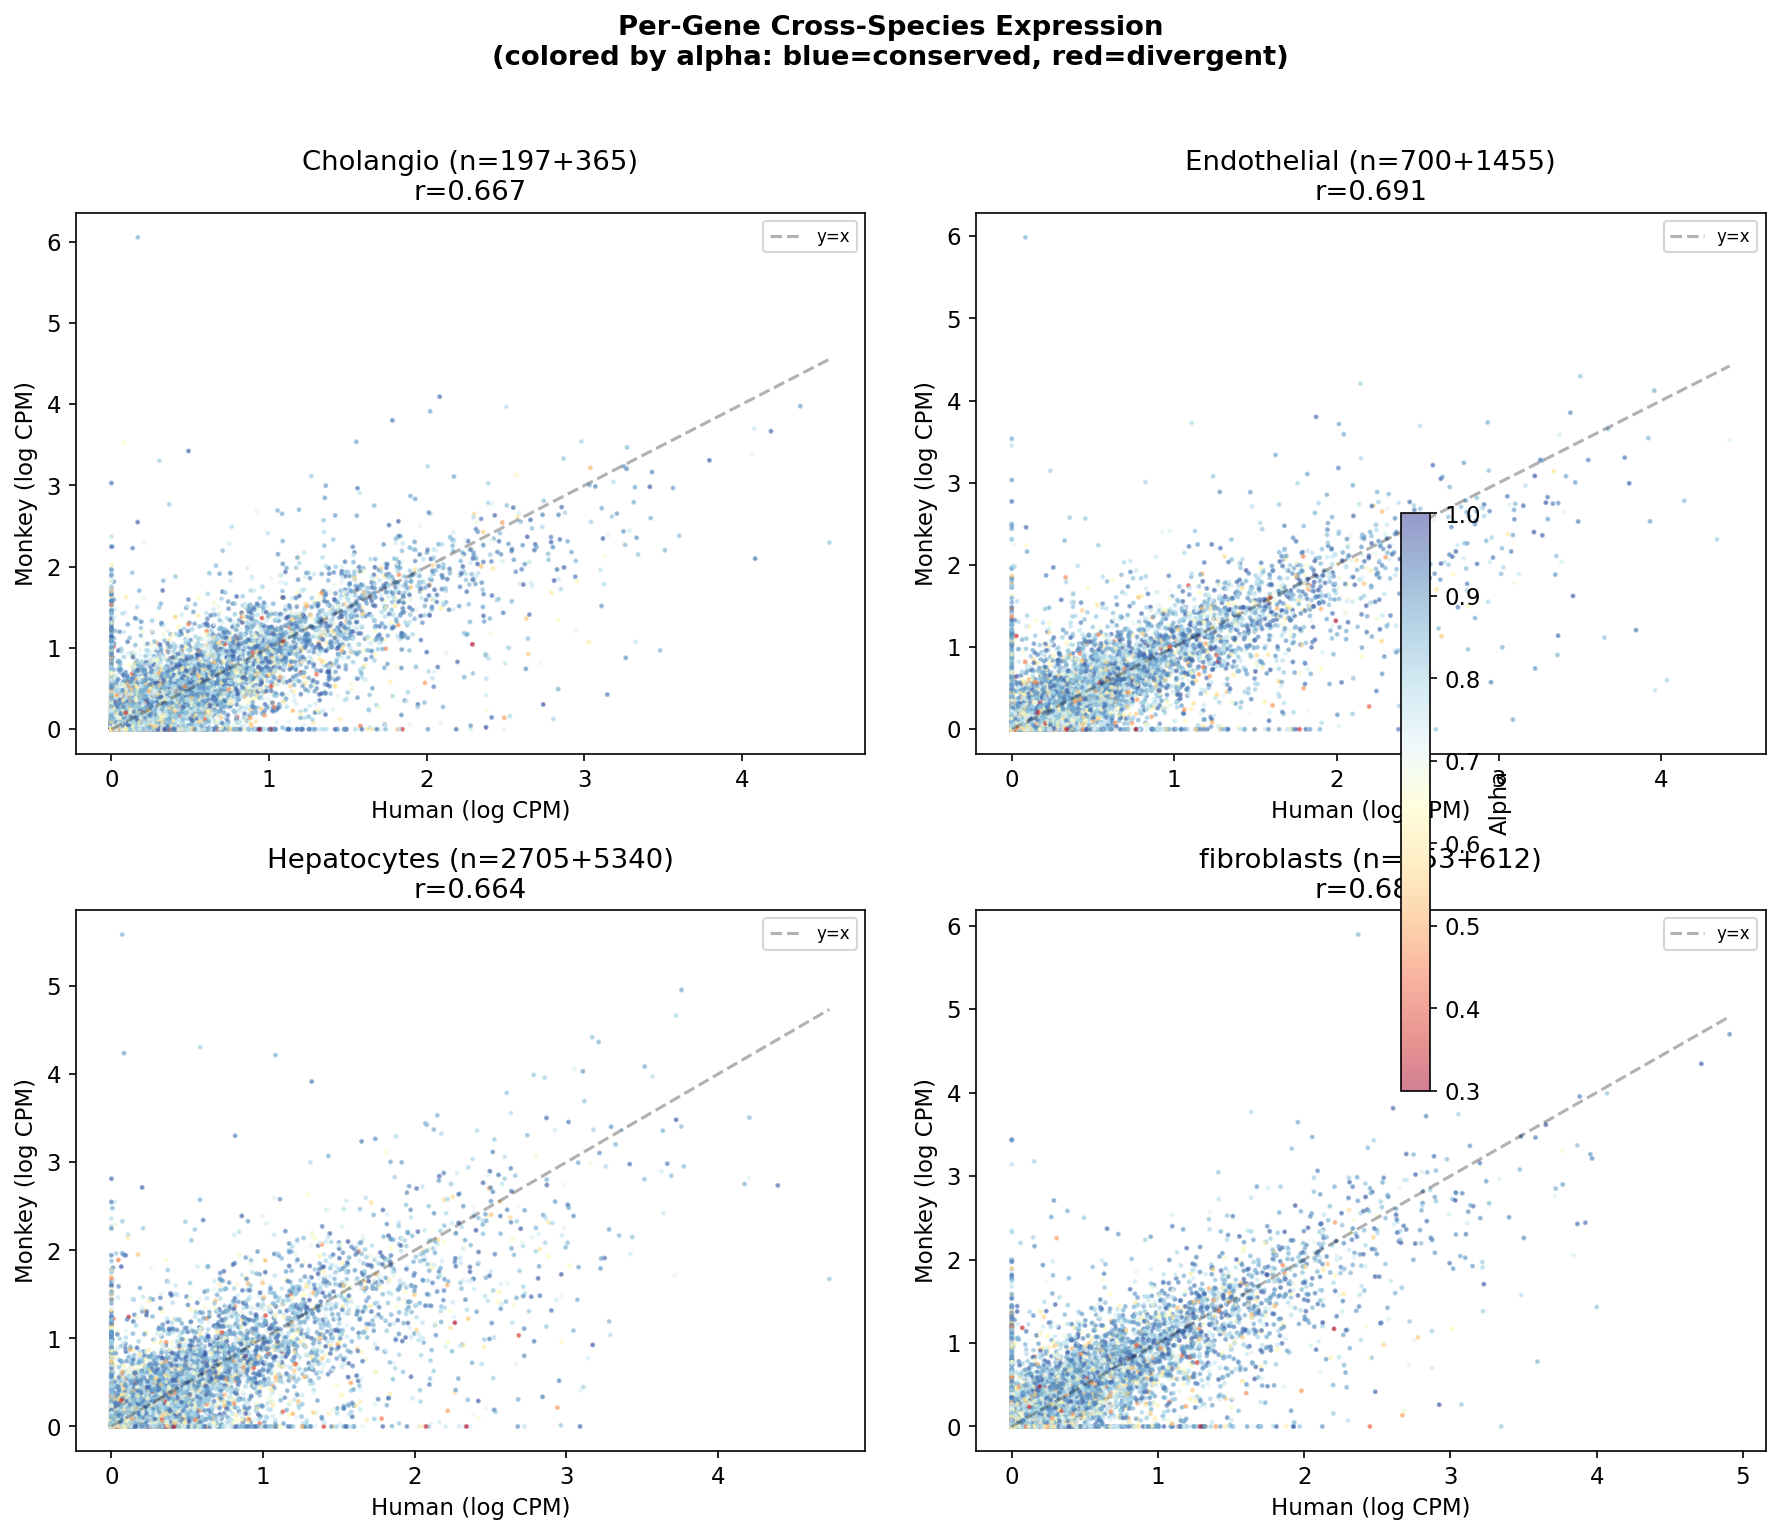

In [3]:
shared_types = sorted(set(cell_types[species==0]) & set(cell_types[species==1]))

# Per-cell-type cross-species correlation vs alpha
lib = X_dense.sum(axis=1, keepdims=True).clip(min=1)
frac = X_dense / lib

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax_idx, ctype in enumerate(shared_types[:4]):
    ax = axes[ax_idx]
    mask0 = (cell_types == ctype) & (species == 0)
    mask1 = (cell_types == ctype) & (species == 1)
    
    # Per-species mean expression for this cell type
    mean0 = np.log1p(1e4 * frac[mask0].mean(0))
    mean1 = np.log1p(1e4 * frac[mask1].mean(0))
    
    # Color by alpha
    sc = ax.scatter(mean0, mean1, s=2, alpha=0.5, c=alpha, cmap='RdYlBu', 
                    vmin=0.3, vmax=1.0, rasterized=True)
    ax.plot([0, mean0.max()], [0, mean0.max()], 'k--', alpha=0.3, label='y=x')
    
    r, _ = spearmanr(mean0, mean1)
    ax.set_xlabel('Human (log CPM)')
    ax.set_ylabel('Monkey (log CPM)')
    ax.set_title(f'{ctype} (n={mask0.sum()}+{mask1.sum()})\nr={r:.3f}')
    ax.legend(fontsize=8)

plt.colorbar(sc, ax=axes, label='Alpha', shrink=0.5)
plt.suptitle('Per-Gene Cross-Species Expression\n(colored by alpha: blue=conserved, red=divergent)', 
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 3. Shared Decoder Quality

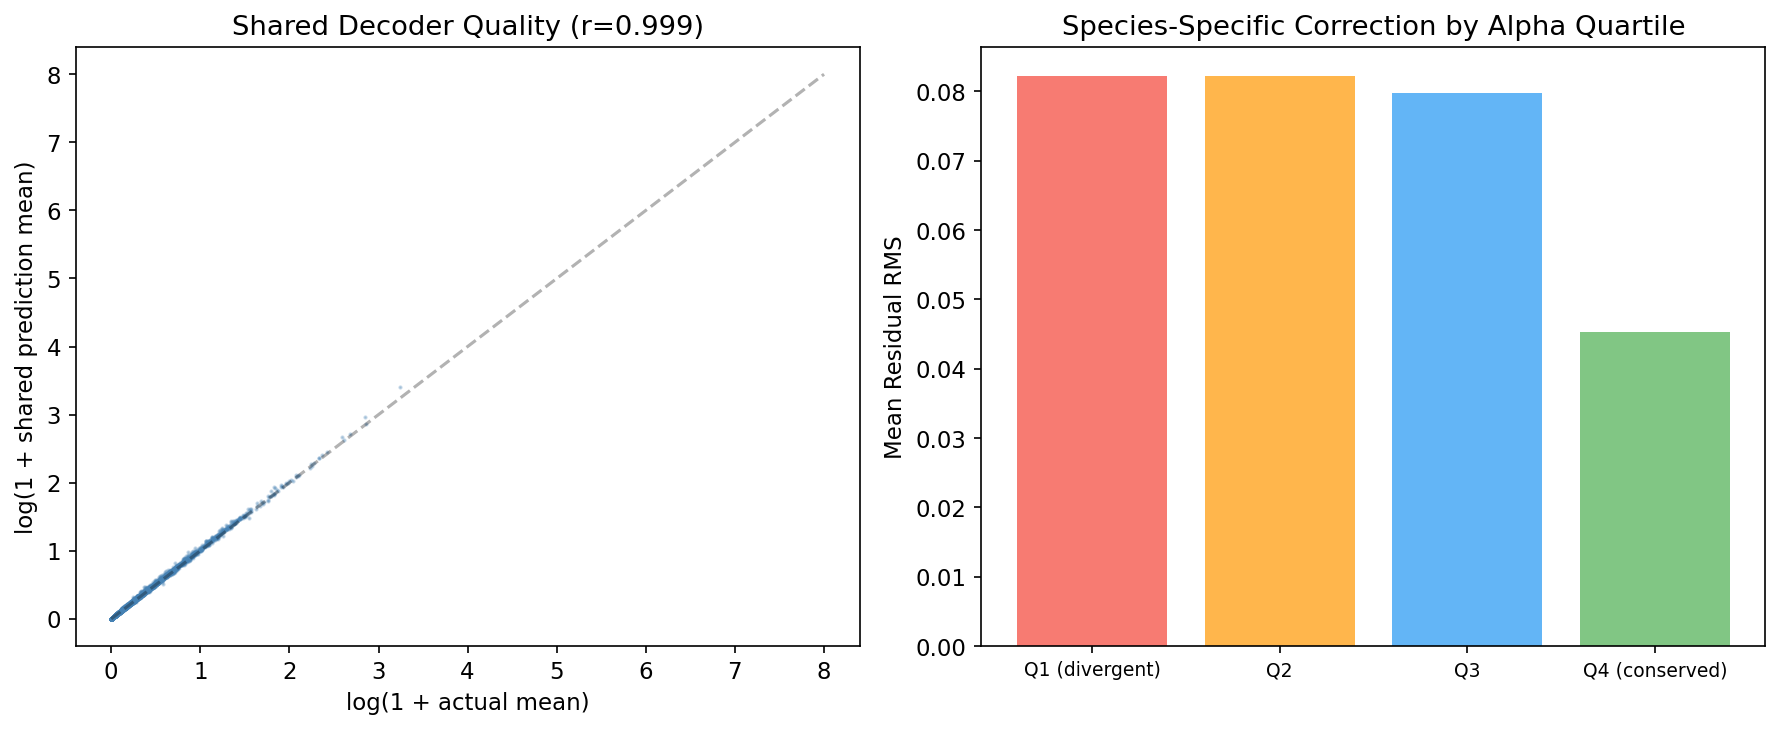

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Shared decoder output vs actual expression
ax = axes[0]
actual_mean = X_dense.mean(0)
r_shared, _ = spearmanr(np.log1p(mu_shared_mean), np.log1p(actual_mean))
ax.scatter(np.log1p(actual_mean), np.log1p(mu_shared_mean), s=1, alpha=0.3, c='steelblue', rasterized=True)
ax.plot([0, 8], [0, 8], 'k--', alpha=0.3)
ax.set_xlabel('log(1 + actual mean)')
ax.set_ylabel('log(1 + shared prediction mean)')
ax.set_title(f'Shared Decoder Quality (r={r_shared:.3f})')

# Residual by alpha quartile
ax = axes[1]
quartiles = np.quantile(alpha, [0.25, 0.5, 0.75])
q_idx = np.digitize(alpha, quartiles)
q_labels = ['Q1 (divergent)', 'Q2', 'Q3', 'Q4 (conserved)']
q_means = [residual_rms[q_idx == qi].mean() for qi in range(4)]
ax.bar(range(4), q_means, color=['#F44336', '#FF9800', '#2196F3', '#4CAF50'], alpha=0.7)
ax.set_xticks(range(4))
ax.set_xticklabels(q_labels, fontsize=9)
ax.set_ylabel('Mean Residual RMS')
ax.set_title('Species-Specific Correction by Alpha Quartile')

plt.tight_layout()
plt.show()

## 4. Seed Reproducibility Check

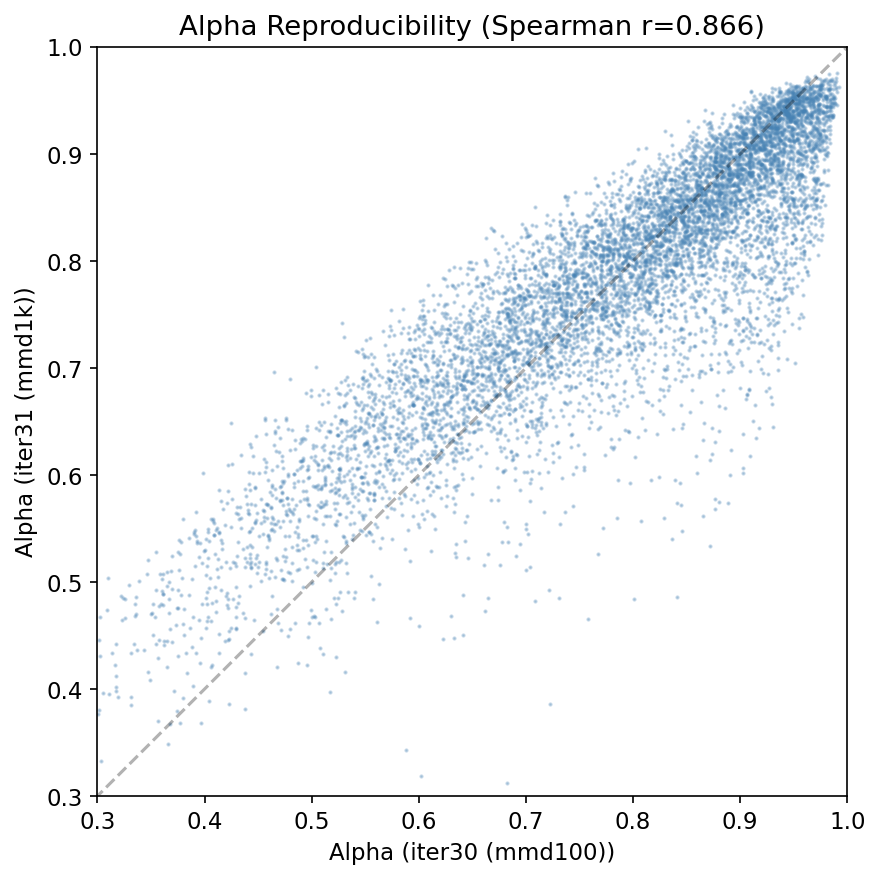

Alpha ranking correlation between runs: r=0.866
Mean absolute difference: 0.0532


In [5]:
# Compare alpha from different runs to check reproducibility
import os

runs_to_compare = [
    ('iter30 (mmd100)', '../training/runs/iter30-mmd-masked-detached/final_state.npz'),
    ('iter31 (mmd1k)', '../training/runs/iter31-mmd1k-masked-detached/final_state.npz'),
]

alphas = {}
for name, path in runs_to_compare:
    if os.path.exists(path):
        s = np.load(path)
        alphas[name] = s['alpha']

if len(alphas) >= 2:
    keys = list(alphas.keys())
    a1, a2 = alphas[keys[0]], alphas[keys[1]]
    r, _ = spearmanr(a1, a2)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(a1, a2, s=1, alpha=0.3, c='steelblue', rasterized=True)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel(f'Alpha ({keys[0]})')
    ax.set_ylabel(f'Alpha ({keys[1]})')
    ax.set_title(f'Alpha Reproducibility (Spearman r={r:.3f})')
    ax.set_xlim(0.3, 1); ax.set_ylim(0.3, 1)
    plt.tight_layout()
    plt.show()
    
    print(f'Alpha ranking correlation between runs: r={r:.3f}')
    print(f'Mean absolute difference: {np.abs(a1 - a2).mean():.4f}')
else:
    print('Need at least 2 runs for reproducibility check')

## 5. Expectation Summary Table

In [6]:
# Load and display expectation results
import json

summary_path = '../training/runs/iter31-mmd1k-masked-detached/summary.json'
if os.path.exists(summary_path):
    with open(summary_path) as f:
        summary = json.load(f)
    print('Expectation Summary:')
    for k, v in sorted(summary.items()):
        if isinstance(v, (int, float, bool)):
            print(f'  {k}: {v}')
else:
    print('Summary not found. Run check_expectations.py first.')

# Key metrics summary
print('\n=== Key Metrics ===')
print(f'Alpha mean: {alpha.mean():.4f} +/- {alpha.std():.4f}')
print(f'Alpha range: [{alpha.min():.3f}, {alpha.max():.3f}]')
print(f'Delta-alpha bidirectional: {(delta_alpha>0.02).mean():.0%} pos, {(delta_alpha<-0.02).mean():.0%} neg')
print(f'Alpha-prior correlation: {spearmanr(prior, alpha)[0]:.3f}')
print(f'L-shape (alpha vs residual): {spearmanr(alpha, residual_rms)[0]:.3f}')
print(f'FQR active fraction: {(state["S_g_ema"]>0).mean():.0%}')

Summary not found. Run check_expectations.py first.

=== Key Metrics ===
Alpha mean: 0.7831 +/- 0.1216
Alpha range: [0.135, 0.976]
Delta-alpha bidirectional: 20% pos, 43% neg
Alpha-prior correlation: 0.921
L-shape (alpha vs residual): -0.339
FQR active fraction: 61%
